# Fuel-Cost Relief and U.S. Airline Passenger-Mile Growth
### Executable research paper · 2026-10-27 · 15 canonical chapters

**Status: REPRODUCED MACRO PILOT, NOT HISTORICAL PIT, NOT INVESTABLE EQUITY ALPHA.** This notebook is an independent narrative and computational record, not a thin wrapper. All data come from inherited, frozen official-series snapshots, and no security-return inference is made. See `README.md` and `data/source_register.csv` for provenance.

## 01. Abstract

**Question.** Does an oil-cost relief score, observed with a two-month buffer, predict three-month-ahead annual growth in U.S. air revenue passenger miles beyond persistence and travel-service controls? The reference target is the BTS *all-service* U.S. air-carrier aggregate, not airline company earnings. We predeclare a fixed WTI annual/quarterly blend, a release-purged expanding window, fixed Ridge regularization and same-origin baselines. The final verdict must be based on executed scorecards, not a hypothesized effect.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np, pandas as pd
from IPython.display import display, SVG, Markdown
from analysis import (load_frozen, build_panel, log_growth, walk_forward, scorecard, rmse_gain, placebo, circular_bootstrap, exposure_sensitivity, leave_year_out, regime_sensitivity, alternative_horizons, ablations, block_shuffle, StudyConfig, MIN_TRAIN, HORIZON, RELEASE_LAG, ALPHA, WEIGHT_YOY)
ROOT=Path.cwd()
assert (ROOT/'data/source_register.csv').exists()
print('Frozen research root:',ROOT.name,'| horizon:',HORIZON,'| feature buffer:',RELEASE_LAG,'| ridge alpha:',ALPHA)

Frozen research root: airline_study | horizon: 3 | feature buffer: 2 | ridge alpha: 15.0


## 02. Research Design & Hypotheses

**H1 (cost channel):** falling crude-oil costs precede higher passenger-mile growth after lagged pass-through into airline capacity or fares. **H2 (incremental):** adding the oil score lowers OOS RMSE relative to an airline/lodging/foodservice control model. **H3 (robustness):** any gain survives block-aware placebo, uncertainty, exposure-weight changes and regimes. The **null** is no incremental improvement. Failure is a negative primary RMSE gain or unstable positive subperiod effects. Counterthesis: oil prices may proxy global demand, while jet-fuel cracks, hedging, ticket prices and aircraft constraints break the chain.

In [2]:
design=pd.DataFrame({'rule':['Target','Formation inputs','Training-label purge','Minimum train origins','Ridge alpha','Oil annual/quarterly weights','Primary metric'], 'predeclared':['100 log(RPM[t+3]/RPM[t-9])','all dated t-2 or earlier','train target release s+3+2 <= t','36','15','0.70 / 0.30','control RMSE minus oil-augmented RMSE']});display(design)

,rule,predeclared
0,Target,100 log(RPM[t+3]/RPM[t-9])
1,Formation inputs,all dated t-2 or earlier
2,Training-label purge,train target release s+3+2 <= t
3,Minimum train origins,36
4,Ridge alpha,15
5,Oil annual/quarterly weights,0.70 / 0.30
6,Primary metric,control RMSE minus oil-augmented RMSE


## 03. Industry Context

IATA's 2025-06-02 global airline outlook estimated jet fuel at 25.8% of 2025 operating costs ([source](https://www.iata.org/en/pressroom/2025-releases/2025-06-02-01/)); that estimate is **not a U.S.-only realized cost ratio**. WTI crude is not jet fuel, and a low oil price can coincide with weak macro demand. BTS AIRRPMTSID11 includes scheduled and unscheduled domestic/international service by U.S. carriers. Exact U.S. revenue corresponding to this aggregate is **UNKNOWN** and never fabricated.

In [3]:
raw=load_frozen(ROOT)
print('Merged raw months:',len(raw),'| start/end:',raw.date.min().date(),raw.date.max().date())
display(raw[['date','AIRRPMTSID11','CES7072100001','CES7072200001','wti_usd_barrel']].tail(8))

Merged raw months: 153 | start/end: 2014-01-01 2026-09-01


,date,AIRRPMTSID11,CES7072100001,CES7072200001,wti_usd_barrel
145,2026-02-01,96177487.0,1921.8,12327.7,64.51
146,2026-03-01,96526471.0,1936.4,12355.2,91.38
147,2026-04-01,95242878.0,1924.1,12360.1,100.32
148,2026-05-01,95217510.0,1938.2,12385.0,102.13
149,2026-06-01,94921559.0,1916.1,12378.0,84.81
150,2026-07-01,NaN,1913.4,12348.4,80.46
151,2026-08-01,NaN,1920.1,12382.2,83.90
152,2026-09-01,NaN,1916.5,12393.0,97.31


In [4]:
qa=pd.DataFrame({'series':['BTS passenger miles','BLS lodging payroll','BLS foodservice payroll','EIA WTI','EIA Henry Hub'], 'nonmissing':[raw[c].notna().sum() for c in ['AIRRPMTSID11','CES7072100001','CES7072200001','wti_usd_barrel','henry_hub_usd_mmbtu']], 'minimum':[raw[c].min() for c in ['AIRRPMTSID11','CES7072100001','CES7072200001','wti_usd_barrel','henry_hub_usd_mmbtu']]});display(qa)
assert raw.loc[raw.date==pd.Timestamp('2026-06-01'),'AIRRPMTSID11'].iloc[0]==94921559
assert np.isclose(raw.loc[raw.date==pd.Timestamp('2026-09-01'),'wti_usd_barrel'].iloc[0],97.31)

,series,nonmissing,minimum
0,BTS passenger miles,150,2877804.00
1,BLS lodging payroll,153,1056.60
2,BLS foodservice payroll,153,6317.30
3,EIA WTI,153,16.55
4,EIA Henry Hub,153,1.49


## 04. Data & Source Integrity

Grade A = official BTS/BLS/EIA data publisher or SEC filing, B = FRED distribution metadata, C = dated industry commentary/estimate; grading is not a guarantee of point-in-time fidelity. Raw data are **inherited** from the already-frozen 2026-10-26 hospitality and 2026-10-08 energy snapshots. The exact underlying original release for each 2014–2025 observation is **UNKNOWN**. No interpolation is applied; absent BTS July–September 2026 targets remain missing.

In [5]:
sources=pd.read_csv(ROOT/'data/source_register.csv')
display(sources[['id','grade','publisher','series','publication_or_update_date','vintage','role']])

,id,grade,publisher,series,publication_or_update_date,vintage,role
0,A1,A,U.S. Bureau of Transportation Statistics,AIRRPMTSID11,2026-10-01 09:01 CDT (FRED latest update),fixed latest-revised snapshot; historic vintag...,Independent airline activity target and persis...
1,A2,A,U.S. Energy Information Administration,WTI Cushing monthly spot,2026-10-08 mirror commit (original observation...,frozen 2026-10-08 mirror; historical vintages ...,Upstream oil price proxy; not jet fuel price
2,A3,A,U.S. Bureau of Labor Statistics,CES7072100001,2026-10-02 08:26 CDT (FRED latest update),fixed latest-revised CES; historical vintages ...,Accommodation demand control proxy
3,A4,A,U.S. Bureau of Labor Statistics,CES7072200001,2026-10-02 08:26 CDT (FRED latest update),fixed latest-revised CES; historical vintages ...,Foodservice demand control proxy
4,B1,B,Federal Reserve Bank of St. Louis FRED,FRED release metadata,2026-10-01,Latest metadata only,Distribution and release metadata (not indepen...
5,C1,C,International Air Transport Association,Global airline fuel operating-cost outlook,2025-06-02,Publication dated 2025-06-02,Industry mechanism and qualitative exposure co...
6,A5,A,U.S. Securities and Exchange Commission,DAL 2025 Form 10-K,2026-02-10 accepted (filing date 2026-02-11),2025 filing,Qualitative company exposure map ONLY; not in ...
7,A6,A,U.S. Securities and Exchange Commission,UAL 2025 Form 10-K,2026-02 (filing day not independently verified),2025 filing,Qualitative company exposure map ONLY
8,A7,A,Southwest Airlines Investor Relations,LUV 2024 Form 10-K,2025-02-07,2024 filing,Qualitative company exposure and hedge caveat ...


In [6]:
raw_hashes={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [ROOT/'data/bts_bls_frozen_2026-10-26.csv',ROOT/'data/eia_energy_frozen_2026-10-08.csv']};display(pd.Series(raw_hashes,name='SHA-256'))
assert len(sources)>=6 and set(sources.grade)=={'A','B','C'}

bts_bls_frozen_2026-10-26.csv       98ad34cabef652c021869fcfa74515a322272ddfb53c3e...
eia_energy_frozen_2026-10-08.csv    312227bacc5ecf4a6e997bf03bbede714bf06256caa18d...
Name: SHA-256, dtype: object

## 05. Point-in-Time Availability

**Formation t** uses all features at **t−2**, including airline persistence, BLS lodging/foodservice growth and WTI growth. At t, a training label from origin s is admissible only if **s+3+2≤t**. This avoids training on targets not yet observable under the assumed two-month release buffer, but it cannot undo revised BTS seasonal factors, CES benchmark changes or unarchived EIA corrections. A current release date does **not** validate historical PIT. This is a retrospective falsification exercise.

In [7]:
panel=build_panel(raw)
display(panel[['date','target_month','available_month','air_persistence','oil_relief','target_air_yoy']].head(7))
print('Eligible formation rows:',len(panel),'| first:',panel.date.min().date(),'| last:',panel.date.max().date())

,date,target_month,available_month,air_persistence,oil_relief,target_air_yoy
0,2015-03-01,2015-06-01,2015-08-01,3.011121,66.076090,4.375240
1,2015-04-01,2015-07-01,2015-09-01,3.136490,60.416939,4.851192
2,2015-05-01,2015-08-01,2015-10-01,2.802195,58.648508,5.777554
3,2015-06-01,2015-09-01,2015-11-01,2.894242,39.712361,5.669597
4,2015-07-01,2015-10-01,2015-12-01,3.439335,33.367877,6.369529
5,2015-08-01,2015-11-01,2016-01-01,4.375240,33.191233,4.442999
6,2015-09-01,2015-12-01,2016-02-01,4.851192,51.763049,5.532137


Eligible formation rows: 133 | first: 2015-03-01 | last: 2026-03-01


In [8]:
# Check no target label in the eligible training set can postdate the formation.
for ix in [0,len(panel)//2,len(panel)-1]:
    t=panel.date.iloc[ix]
    eligible=panel.loc[(panel.available_month<=t)&(panel.date<t)]
    assert (eligible.target_month<t).all()
print('Target availability check passed at beginning, middle and end; release lag remains assumed, not audited.')

Target availability check passed at beginning, middle and end; release lag remains assumed, not audited.


## 06. Factor Construction

With WTI monthly price P, define \(g_{12,t}=100\log(P_{t-2}/P_{t-14})\) and \(g_{3,t}=100\log(P_{t-2}/P_{t-5})\). The oil-cost relief score is \(F_t=-(0.70g_{12,t}+0.30g_{3,t})\). **No** future global mean or fitted exposure weights are used. A higher score means cheaper oil, not automatically higher airline passenger demand. The target is \(Y_{t+3}=100\log(RPM_{t+3}/RPM_{t-9})\).

In [9]:
check=-(.7*panel.wti_yoy+.3*panel.wti_3m)
assert np.allclose(check,panel.oil_relief)
print('Factor identity verified on',len(check),'formation rows')
display(panel[['date','wti_yoy','wti_3m','oil_relief','target_air_yoy']].describe().round(2))

Factor identity verified on 133 formation rows


,date,wti_yoy,wti_3m,oil_relief,target_air_yoy
count,133,133.00,133.00,133.00,133.00
mean,2020-08-31 04:19:50.977443584,-3.29,-0.45,2.43,2.37
min,2015-03-01 00:00:00,-135.03,-124.57,-97.28,-341.18
25%,2017-12-01 00:00:00,-24.18,-9.36,-14.95,2.10
50%,2020-09-01 00:00:00,-6.12,-0.10,3.71,4.15
75%,2023-06-01 00:00:00,19.00,11.74,16.83,7.19
max,2026-03-01 00:00:00,131.62,90.01,131.89,279.19
std,NaN,39.05,22.67,31.17,75.67


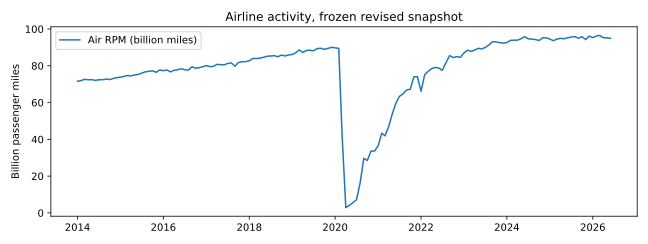

In [10]:
display(SVG(filename=str(ROOT/'figures/01_airline_activity.svg')))

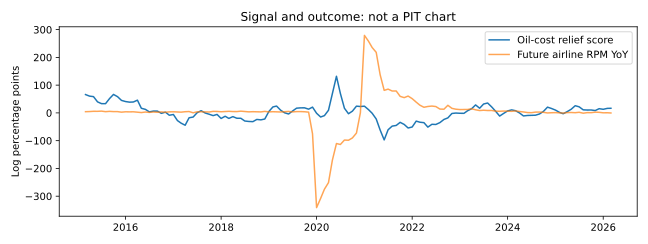

In [11]:
display(SVG(filename=str(ROOT/'figures/02_signal_target.svg')))

## 07. Exposure & Transmission

Economic chain: WTI → jet-fuel proxy → airline costs → fares/capacity → passenger miles. The three issuer examples below document fuel exposure **as disclosed in later filings**, not an issuer-level historical signal. The 70/30 parameter weights *oil-change horizons*, not company weights. No company panel is fitted and no historical firm-level exposure is inferred. Consequently leave-one-company-out is **not applicable**; a leave-one-year-out diagnostic is used later.

In [12]:
exposure=pd.read_csv(ROOT/'data/company_exposure_map.csv');display(exposure[['issuer','ticker','reference_period','as_of_disclosure','mechanism','quantitative_weight_used','historical_exposure_PIT']])
assert (exposure.historical_exposure_PIT=='NO').all()

,issuer,ticker,reference_period,as_of_disclosure,mechanism,quantitative_weight_used,historical_exposure_PIT
0,Delta Air Lines,DAL,FY2025,2026-02-10,Fuel cost material; 2025 fuel costs 17% of ope...,NONE,NO
1,United Airlines,UAL,FY2025,2026-02 UNKNOWN exact day,"Aircraft fuel expense USD 11,396m vs total ope...",NONE,NO
2,Southwest Airlines,LUV,FY2024,2025-02-07,Fuel derivatives and Brent-based hedging discl...,NONE,NO


## 08. Outcomes & Baselines

The exact same released-label training origins and target months feed historical mean, last-known airline persistence, macro-control Ridge, augmented Ridge and oil-only Ridge. Fixed Ridge alpha 15, train-only centering/scaling and ±6 z clipping prevent test-period standardization leakage. We do not tune alpha, weights or transformations to this OOS period. There are no issuer total returns, so IC, long-short spread, benchmark-adjusted equity return and trading costs are **not defined**.

In [13]:
oos=walk_forward(panel)
assert len(oos)==93 and oos.n_train.min()>=36
print('OOS origins:',len(oos),'| earliest/latest:',oos.formation_date.min().date(),oos.formation_date.max().date(),'| min training:',oos.n_train.min())
display(oos.head(5))

OOS origins: 93 | earliest/latest: 2018-07-01 2026-03-01 | min training: 36


,formation_date,target_date,n_train,actual,historical_mean,air_persistence,macro_control,oil_augmented,oil_only
0,2018-07-01,2018-10-01,36,4.827860,3.841816,4.869411,5.291782,4.954632,3.456833
1,2018-08-01,2018-11-01,37,3.731018,3.892186,5.705509,5.175363,4.829782,3.569167
2,2018-09-01,2018-12-01,38,4.358133,3.918026,4.874134,5.013251,4.882544,3.623469
3,2018-10-01,2019-01-01,39,4.023866,3.939087,4.739372,4.807148,4.893284,3.726038
4,2018-11-01,2019-02-01,40,3.572545,3.996646,6.241448,4.693700,4.737920,3.834355


In [14]:
scores=scorecard(oos)
display(scores.round(3))
assert np.isclose(scores.set_index('model').loc['oil_augmented','rmse'],107.775732,atol=.001)
print('Predeclared control-minus-full RMSE gain:',round(rmse_gain(oos),3),'log-pp')

,model,n,rmse,mae,bias
0,historical_mean,93,94.303,45.955,-3.256
1,air_persistence,93,111.133,53.811,0.227
2,macro_control,93,107.082,53.197,-0.767
3,oil_augmented,93,107.776,53.544,-0.598
4,oil_only,93,93.117,44.704,-1.531


Predeclared control-minus-full RMSE gain: -0.694 log-pp


## 09. Empirical Findings

**Primary comparison fails:** macro-control RMSE 107.082 log-pp vs oil-augmented 107.776 (gain −0.694). The historical mean scores 94.303; oil-only scores 93.117 but this is a secondary, uncontrolled comparison and cannot rescue the failed H2. COVID shock months make both RMSE and fitted coefficients unstable. These numbers are computed, not claimed from the narrative.

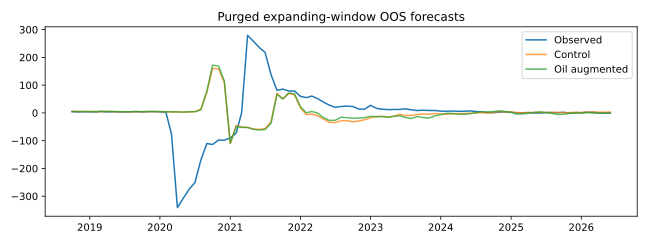

In [15]:
display(SVG(filename=str(ROOT/'figures/03_oos_predictions.svg')))

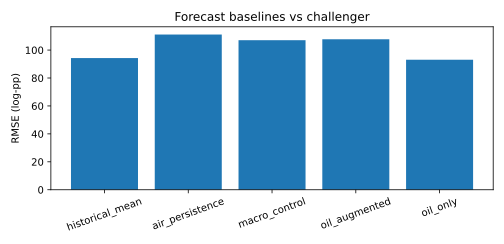

In [16]:
display(SVG(filename=str(ROOT/'figures/04_scorecard.svg')))

In [17]:
err=oos.assign(control_error=oos.macro_control-oos.actual,augmented_error=oos.oil_augmented-oos.actual)
display(err[['formation_date','target_date','actual','control_error','augmented_error']].reindex(err.control_error.abs().sort_values(ascending=False).index).head(8))

,formation_date,target_date,actual,control_error,augmented_error
18,2020-01-01,2020-04-01,-341.179078,344.762144,344.717172
30,2021-01-01,2021-04-01,279.193148,-331.032182,-331.774034
31,2021-02-01,2021-05-01,258.287950,-316.067879,-317.449426
19,2020-02-01,2020-05-01,-307.926878,310.929025,310.849037
32,2021-03-01,2021-06-01,235.489959,-295.061186,-297.146845
20,2020-03-01,2020-06-01,-274.916932,278.894862,278.841411
33,2021-04-01,2021-07-01,218.216176,-274.785560,-278.166472
24,2020-07-01,2020-10-01,-113.762429,273.736227,285.615052


## 10. Robustness & Placebos

The placebo shuffles **12-month contiguous blocks** of the signal across the formation panel, keeps within-block order and refits the augmented Ridge at every OOS origin. This is a time-series-aware exploratory falsification, **not** an exact randomization p-value because the block exchangeability assumptions are not verified. The paired circular-block bootstrap preserves local error dependence and reports an interval for the RMSE *difference*. The oil-horizon blend perturbation samples 1,000 predeclared weights but never picks a best performer for the headline result.

In [18]:
pnull=placebo(panel,rmse_gain(oos),n=1000)
print('Block-shuffle refits:',len(pnull),'| exploratory tail fraction:',round(float(np.mean(pnull.gain_rmse>=rmse_gain(oos))),3))
assert len(pnull)==1000
assert np.allclose(pnull.gain_rmse,pd.read_csv(ROOT/'results/block_placebo_1000.csv').gain_rmse)

Block-shuffle refits: 1000 | exploratory tail fraction: 0.615


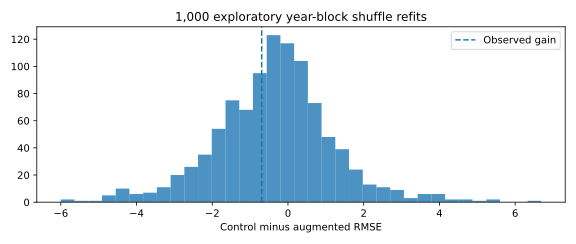

In [19]:
display(SVG(filename=str(ROOT/'figures/05_placebo.svg')))

In [20]:
boots=circular_bootstrap(oos,n=2000)
ci=np.quantile(boots.gain_rmse,[.025,.975])
print('Paired 12-month circular-block bootstrap:',len(boots),'| 95% percentile interval:',np.round(ci,3))
assert len(boots)==2000 and np.allclose(boots.gain_rmse,pd.read_csv(ROOT/'results/block_bootstrap_2000.csv').gain_rmse)

Paired 12-month circular-block bootstrap: 2000 | 95% percentile interval: [-2.032  2.304]


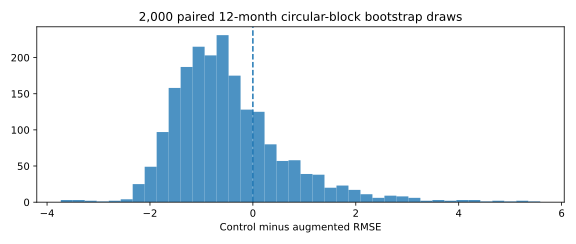

In [21]:
display(SVG(filename=str(ROOT/'figures/06_bootstrap.svg')))

In [22]:
weights=exposure_sensitivity(panel,n=1000)
print('Oil annual-weight perturbations:',len(weights),'| positive control gains:',int((weights.gain_rmse>0).sum()))
assert len(weights)==1000 and np.allclose(weights.gain_rmse,pd.read_csv(ROOT/'results/exposure_sensitivity_1000.csv').gain_rmse)

Oil annual-weight perturbations: 1000 | positive control gains: 0


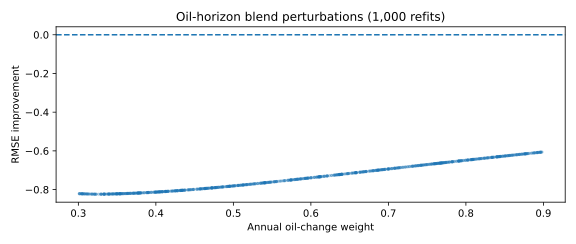

In [23]:
display(SVG(filename=str(ROOT/'figures/07_exposure.svg')))

## 11. Regime Sensitivity

Pre/post-COVID windows are **diagnostic slices of the same OOS predictions**, not independent holdouts. Removing 2020–21 changes the sign, and the 2024+ sample changes it back. The wide 1–6 month horizon and 2–4 month lag grid is a robustness stress test, **not** an optimization search. Leave-one-year-out is a descriptive influence check; issuer-level leave-one-out cannot be run without firm data.

In [24]:
reg=regime_sensitivity(oos);display(reg.round(3))
assert np.isclose(reg.set_index('regime').loc['exclude_2020_2021','gain_rmse'],2.289389,atol=.001)

,regime,n,gain_rmse
0,all,93,-0.694
1,exclude_2020_2021,69,2.289
2,pre_2020,15,-0.098
3,2022_plus,54,2.589
4,2024_plus,30,-0.929


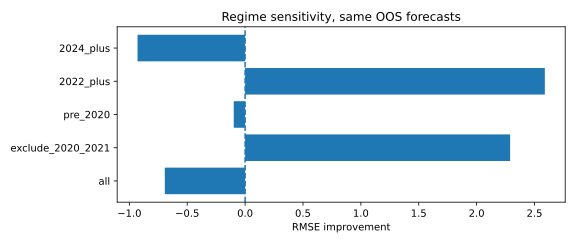

In [25]:
display(SVG(filename=str(ROOT/'figures/09_regimes.svg')))

In [26]:
loo=leave_year_out(oos);display(loo.round(3))

,excluded_formation_year,n,gain_rmse
0,2018,87,-0.717
1,2019,81,-0.744
2,2020,81,0.097
3,2021,81,-0.666
4,2022,81,-1.208
5,2023,81,-0.596
6,2024,81,-0.733
7,2025,81,-0.737
8,2026,90,-0.706


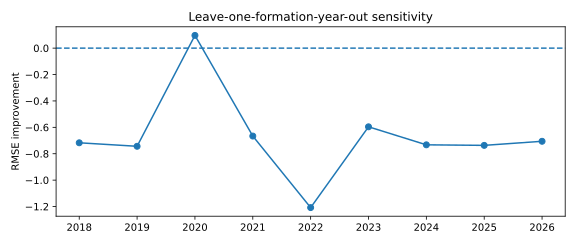

In [27]:
display(SVG(filename=str(ROOT/'figures/08_leave_year.svg')))

In [28]:
horizons=alternative_horizons(raw);display(horizons.round(3))
print('Robustness sign counts:',int((horizons.gain_rmse>0).sum()),'positive of',len(horizons))

,horizon_months,feature_lag_months,n,gain_rmse
0,1,2,97,0.968
1,1,3,95,-0.621
2,1,4,93,-0.694
3,3,2,93,-0.694
4,3,3,91,1.037
5,3,4,89,1.531
6,6,2,87,0.096
7,6,3,85,-6.423
8,6,4,83,-10.758


Robustness sign counts: 4 positive of 9


In [29]:
ablation=ablations(panel);display(ablation.round(3))
print('Removing foodservice controls flips the sign:',bool(ablation.set_index('controls').loc['no_food','gain_rmse']>0))

,controls,n,gain_rmse
0,base_all,93,-0.694
1,no_lodging,93,-1.184
2,no_food,93,0.175
3,persistence_only,93,-0.350


Removing foodservice controls flips the sign: True


## 12. Bias Audit & Verdict

**Publication vintage:** not reconstructed; fixed two-month buffer is not proof. **Selection:** target and inherited data were selected retrospectively, with no untouched future holdout. **Survivorship:** BTS aggregate avoids choosing surviving stocks but does not create an issuer panel. **Multiple testing:** regime/lag/ablation comparisons are unadjusted diagnostics. **Cost and execution:** no portfolio exists, so these are not assessed. **Proxy:** WTI is not jet fuel and the refining spread and carrier hedges are missing. **Verdict: negative fixed-snapshot macro lead-factor falsification, no PIT or investable equity-alpha claim.**

In [30]:
audit=pd.DataFrame({'risk':['Historical release/vintage','Overlapping OOS horizons','Issuer selection/survivorship','Multiple testing','Fuel proxy and hedging','Trading costs/returns'], 'status':['UNVERIFIED; conservative lag only','Paired 12-month block bootstrap','NO company panel','Exploratory, not adjusted','WTI != jet fuel','NOT TESTED / N/A']});display(audit)

,risk,status
0,Historical release/vintage,UNVERIFIED; conservative lag only
1,Overlapping OOS horizons,Paired 12-month block bootstrap
2,Issuer selection/survivorship,NO company panel
3,Multiple testing,"Exploratory, not adjusted"
4,Fuel proxy and hedging,WTI != jet fuel
5,Trading costs/returns,NOT TESTED / N/A


## 13. Reproduction

From the study directory run `python run_analysis.py`, `python -m pytest -q tests`, and execute this notebook via `nbclient` or `jupyter nbconvert --execute --inplace`. All code and data are committed with frozen inputs; `logs/` contains observed execution/test records. A separate root-level `python scripts/validate_studies.py` is a structural check, not proof of PIT or numerical validity. This notebook recomputes the OOS forecasts, 1,000 placebo refits, 2,000 bootstrap draws, 1,000 oil-weight refits and multiple robustness checks, comparing them with saved result CSVs.

In [31]:
# Verify computed and frozen artifacts agree to numerical tolerance.
checks={
 'oos_actual':np.allclose(oos.actual,pd.read_csv(ROOT/'results/oos_predictions.csv').actual),
 'oos_full':np.allclose(oos.oil_augmented,pd.read_csv(ROOT/'results/oos_predictions.csv').oil_augmented),
 'scorecard_rmse':np.allclose(scores.rmse,pd.read_csv(ROOT/'results/scorecard.csv').rmse),
 'placebo_1000':np.allclose(pnull.gain_rmse,pd.read_csv(ROOT/'results/block_placebo_1000.csv').gain_rmse),
 'bootstrap_2000':np.allclose(boots.gain_rmse,pd.read_csv(ROOT/'results/block_bootstrap_2000.csv').gain_rmse),
 'weights_1000':np.allclose(weights.gain_rmse,pd.read_csv(ROOT/'results/exposure_sensitivity_1000.csv').gain_rmse)}
display(pd.Series(checks,name='Independent notebook match'));assert all(checks.values())

oos_actual        True
oos_full          True
scorecard_rmse    True
placebo_1000      True
bootstrap_2000    True
weights_1000      True
Name: Independent notebook match, dtype: bool

## 14. Next-Stage Protocol

Build a release-date-indexed archive of historical BTS, BLS, EIA and actual jet-fuel price data, then repeat strictly at each original formation date. Incorporate carrier-quarter fuel gallons, hedges, fare indices, airport capacity, demand shocks and dated SEC filings, with an explicitly defined universe. Test issuer sales/margins separately from dividend/split-adjusted total returns; use a sector/market benchmark, transaction costs, liquidity, multiple-testing correction and a genuinely untouched forward holdout. The present negative result is a useful constraint on that next design.

In [32]:
next_data=pd.DataFrame({'priority':[1,2,3,4,5], 'missing':['Original BTS/EIA/CES vintages','Actual jet fuel spot and crack spreads','Carrier-level fuel/hedging disclosures','Carrier fundamentals with filing dates','Adjusted total returns and execution costs'], 'required_for':['PIT','Cost mechanism','Company exposure','Fundamental lead test','Equity alpha test']});display(next_data)

,priority,missing,required_for
0,1,Original BTS/EIA/CES vintages,PIT
1,2,Actual jet fuel spot and crack spreads,Cost mechanism
2,3,Carrier-level fuel/hedging disclosures,Company exposure
3,4,Carrier fundamentals with filing dates,Fundamental lead test
4,5,Adjusted total returns and execution costs,Equity alpha test


## 15. Sources & Artifacts

Official numerical sources: [BTS air miles](https://fred.stlouisfed.org/series/AIRRPMTSID11), [EIA WTI](https://www.eia.gov/dnav/pet/hist/rwtcm.htm), [BLS lodging](https://fred.stlouisfed.org/series/CES7072100001), [BLS foodservice](https://fred.stlouisfed.org/series/CES7072200001). Mechanism: [IATA 2025-06-02](https://www.iata.org/en/pressroom/2025-releases/2025-06-02-01/). Dated issuer disclosure links: `data/company_exposure_map.csv`. Complete A/B/C metadata and original dates: `data/source_register.csv`. Reproducible outputs: `results/` and `figures/`. The exact historical publication vintages and tradable security outcomes are **UNKNOWN / NOT TESTED**.

In [33]:
print('FINAL VERDICT: NEGATIVE RETROSPECTIVE MACRO PILOT; NO HISTORICAL PIT, NO EQUITY ALPHA')
print('OOS:',len(oos),'| control RMSE:',round(scores.set_index('model').loc['macro_control','rmse'],3),'| augmented:',round(scores.set_index('model').loc['oil_augmented','rmse'],3))
print('Computed diagnostic SVGs:',len(list((ROOT/'figures').glob('*.svg'))),'| source register entries:',len(sources))

FINAL VERDICT: NEGATIVE RETROSPECTIVE MACRO PILOT; NO HISTORICAL PIT, NO EQUITY ALPHA
OOS: 93 | control RMSE: 107.082 | augmented: 107.776
Computed diagnostic SVGs: 9 | source register entries: 9
